# TSA Passenger Complaint & Airport Operations Analysis

## Project Overview

This project examines Transportation Security Administration (TSA) complaint records from January 2015 through January 2024 to identify changes in complaint volume, prominent passenger concerns, differences among major airports, and geographic patterns. Four datasets support six visualizations. The analysis emphasizes what the recorded complaint counts show, while distinguishing complaint volume from passenger-adjusted service quality.


## 1. Import Libraries

In [1]:
from pathlib import Path
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)


## 2. Set Project Paths

**Interpretation:** The notebook identifies the project directory whether Jupyter is launched from the project root or the `notebooks/` folder. It creates a `figures/` directory for reproducible chart exports. The four source CSV files are expected in `data/`; no manual download is needed when the repository contains them.


In [2]:
CURRENT_DIR = Path.cwd()

# Support running from either the project root or the notebooks folder.
if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders ready:")
print(" - data/")
print(" - figures/")


Project folders ready:
 - data/
 - figures/


## 3. Load the Datasets

**Purpose:** Load airport-level, category-level, and subcategory-level TSA complaint records alongside an IATA/ICAO airport reference file. The three complaint datasets represent different breakdowns of the same complaint activity; their totals should **not** be added together.


In [3]:
airport_df = pd.read_csv(
    DATA_DIR / "complaints-by-airport.csv"
)

category_df = pd.read_csv(
    DATA_DIR / "complaints-by-category.csv"
)

subcategory_df = pd.read_csv(
    DATA_DIR / "complaints-by-subcategory.csv"
)

iata_df = pd.read_csv(
    DATA_DIR / "iata-icao.csv"
)

print("All four datasets loaded successfully.")

print("\nComplaints by airport:")
display(airport_df.head())

print("\nComplaints by category:")
display(category_df.head())

print("\nComplaints by subcategory:")
display(subcategory_df.head())

print("\nAirport reference data:")
display(iata_df.head())


All four datasets loaded successfully.

Complaints by airport:


,pdf_report_date,airport,year_month,count
0,2019-02,ABE,2015-01,0
1,2019-02,ABE,2015-02,0
2,2019-02,ABE,2015-03,0
3,2019-02,ABE,2015-04,0
4,2019-02,ABE,2015-05,2



Complaints by category:


,pdf_report_date,airport,category,year_month,count,clean_cat,clean_cat_status
0,2019-02,ABE,Hazardous Materials Safety,2015-01,0,Hazardous Materials Safety,original
1,2019-02,ABE,Mishandling of Passenger Property,2015-01,0,Mishandling of Passenger Property,original
2,2019-02,ABE,Hazardous Materials Safety,2015-02,0,Hazardous Materials Safety,original
3,2019-02,ABE,Mishandling of Passenger Property,2015-02,0,Mishandling of Passenger Property,original
4,2019-02,ABE,Hazardous Materials Safety,2015-03,0,Hazardous Materials Safety,original



Complaints by subcategory:


,pdf_report_date,airport,category,subcategory,year_month,count,clean_cat,clean_subcat,clean_cat_status,clean_subcat_status,is_category_prefix_removed
0,2019-02,ABE,Hazardous Materials Safety,General,2015-01,0,Hazardous Materials Safety,General,original,original,False
1,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-01,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
2,2019-02,ABE,Hazardous Materials Safety,General,2015-02,0,Hazardous Materials Safety,General,original,original,False
3,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-02,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
4,2019-02,ABE,Hazardous Materials Safety,General,2015-03,0,Hazardous Materials Safety,General,original,original,False



Airport reference data:


,country_code,region_name,iata,icao,airport,latitude,longitude
0,AE,Abu Zaby,AAN,OMAL,Al Ain International Airport,24.2617,55.6092
1,AE,Abu Zaby,AUH,OMAA,Abu Dhabi International Airport,24.4330,54.6511
2,AE,Abu Zaby,AYM,NaN,Yas Island Seaplane Base,24.4670,54.6103
3,AE,Abu Zaby,AZI,OMAD,Al Bateen Executive Airport,24.4283,54.4581
4,AE,Abu Zaby,DHF,OMAM,Al Dhafra Air Base,24.2482,54.5477


## 4. Clean and Prepare the Data

**Purpose:** Standardize field names, parse monthly dates, derive calendar fields, remove records without usable airport codes, normalize airport codes, and handle missing complaint counts. These steps support consistent grouping and the airport-code join used in the geographic analysis.


In [4]:
# Standardize column names across all datasets.
for df in [
    airport_df,
    category_df,
    subcategory_df,
    iata_df
]:
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("-", "_")
    )

# Convert date columns.
airport_df["year_month"] = pd.to_datetime(
    airport_df["year_month"]
)

category_df["year_month"] = pd.to_datetime(
    category_df["year_month"]
)

subcategory_df["year_month"] = pd.to_datetime(
    subcategory_df["year_month"]
)

# Create year and month fields.
for df in [
    airport_df,
    category_df,
    subcategory_df
]:
    df["year"] = df["year_month"].dt.year
    df["month"] = df["year_month"].dt.month
    df["month_name"] = df["year_month"].dt.month_name()

# Remove rows with missing or blank airport codes.
for df in [
    airport_df,
    category_df,
    subcategory_df
]:
    df.dropna(
        subset=["airport"],
        inplace=True
    )

    df.drop(
        df[
            df["airport"]
            .astype(str)
            .str.strip()
            .eq("")
        ].index,
        inplace=True
    )

    df["airport"] = (
        df["airport"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

# Standardize airport codes in the reference dataset.
iata_df["iata"] = (
    iata_df["iata"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Replace missing complaint counts with zero.
for df in [
    airport_df,
    category_df,
    subcategory_df
]:
    df["count"] = df["count"].fillna(0)

print("Data cleaning completed successfully.")


Data cleaning completed successfully.


In [5]:
print("Complaints by airport after cleaning:")
display(airport_df.head())

print("\nComplaints by category after cleaning:")
display(category_df.head())

print("\nComplaints by subcategory after cleaning:")
display(subcategory_df.head())

print("\nAirport reference data after cleaning:")
display(iata_df.head())


Complaints by airport after cleaning:


,pdf_report_date,airport,year_month,count,year,month,month_name
0,2019-02,ABE,2015-01-01,0,2015,1,January
1,2019-02,ABE,2015-02-01,0,2015,2,February
2,2019-02,ABE,2015-03-01,0,2015,3,March
3,2019-02,ABE,2015-04-01,0,2015,4,April
4,2019-02,ABE,2015-05-01,2,2015,5,May



Complaints by category after cleaning:


,pdf_report_date,airport,category,year_month,count,clean_cat,clean_cat_status,year,month,month_name
0,2019-02,ABE,Hazardous Materials Safety,2015-01-01,0,Hazardous Materials Safety,original,2015,1,January
1,2019-02,ABE,Mishandling of Passenger Property,2015-01-01,0,Mishandling of Passenger Property,original,2015,1,January
2,2019-02,ABE,Hazardous Materials Safety,2015-02-01,0,Hazardous Materials Safety,original,2015,2,February
3,2019-02,ABE,Mishandling of Passenger Property,2015-02-01,0,Mishandling of Passenger Property,original,2015,2,February
4,2019-02,ABE,Hazardous Materials Safety,2015-03-01,0,Hazardous Materials Safety,original,2015,3,March



Complaints by subcategory after cleaning:


,pdf_report_date,airport,category,subcategory,year_month,count,clean_cat,clean_subcat,clean_cat_status,clean_subcat_status,is_category_prefix_removed,year,month,month_name
0,2019-02,ABE,Hazardous Materials Safety,General,2015-01-01,0,Hazardous Materials Safety,General,original,original,False,2015,1,January
1,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-01-01,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False,2015,1,January
2,2019-02,ABE,Hazardous Materials Safety,General,2015-02-01,0,Hazardous Materials Safety,General,original,original,False,2015,2,February
3,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-02-01,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False,2015,2,February
4,2019-02,ABE,Hazardous Materials Safety,General,2015-03-01,0,Hazardous Materials Safety,General,original,original,False,2015,3,March



Airport reference data after cleaning:


,country_code,region_name,iata,icao,airport,latitude,longitude
0,AE,Abu Zaby,AAN,OMAL,Al Ain International Airport,24.2617,55.6092
1,AE,Abu Zaby,AUH,OMAA,Abu Dhabi International Airport,24.4330,54.6511
2,AE,Abu Zaby,AYM,NaN,Yas Island Seaplane Base,24.4670,54.6103
3,AE,Abu Zaby,AZI,OMAD,Al Bateen Executive Airport,24.4283,54.4581
4,AE,Abu Zaby,DHF,OMAM,Al Dhafra Air Base,24.2482,54.5477


## 5. Complaint Activity by Month and Year

The heatmap sums airport-level complaint counts for each calendar month and year. Darker cells indicate greater recorded complaint volume, making changes across months and years visible without assuming every year has the same reporting coverage.


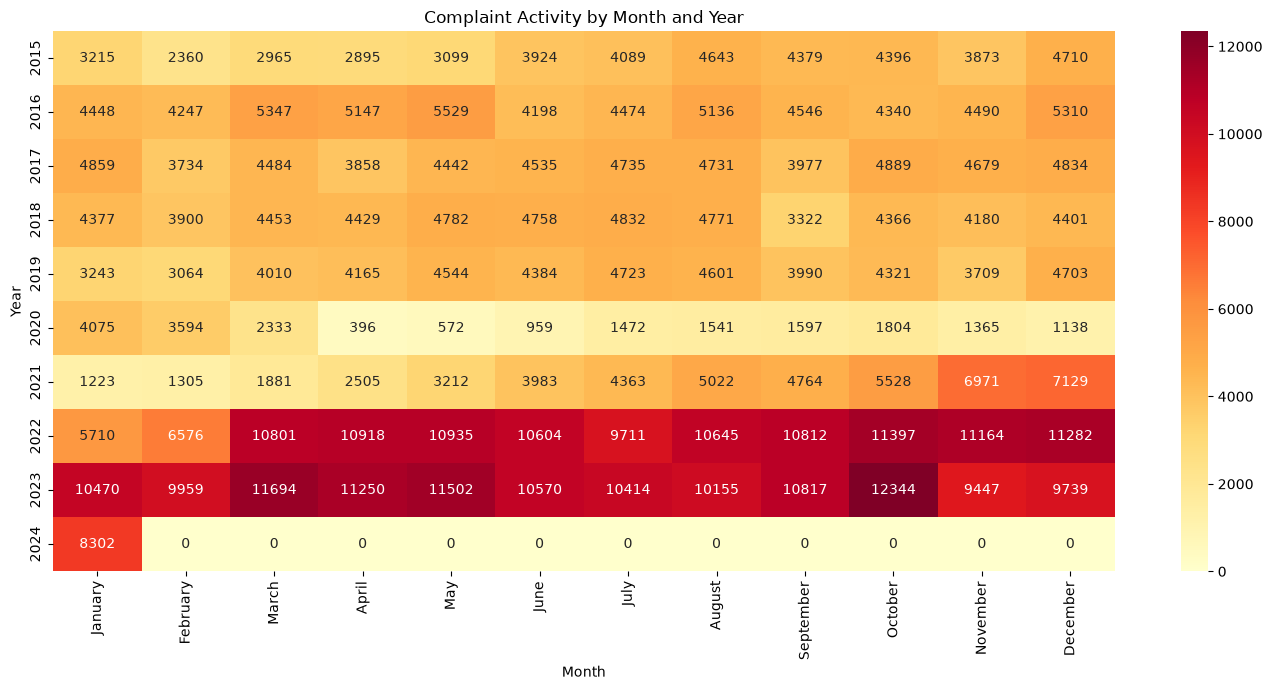

Saved: figures/complaint_activity_by_month_and_year_heatmap.jpg


In [6]:
heatmap_data = (
    airport_df
    .groupby(["year", "month_name"])["count"]
    .sum()
    .reset_index()
)

heatmap_pivot = heatmap_data.pivot_table(
    index="year",
    columns="month_name",
    values="count",
    fill_value=0
)

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

heatmap_pivot = heatmap_pivot[month_order]

plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f"
)

plt.title("Complaint Activity by Month and Year")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()

save_path = (
    FIGURES_DIR
    / "complaint_activity_by_month_and_year_heatmap.jpg"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figures/"
    "complaint_activity_by_month_and_year_heatmap.jpg"
)


### Detailed Interpretation — Monthly and Annual Complaint Activity

**What the heatmap measures.** Each cell represents the sum of recorded complaints across airports for one calendar month. Comparing cells across a row helps reveal month-to-month variation within a year; comparing rows helps reveal broader shifts in reported complaint volume. The color scale represents **absolute counts**, not complaints per passenger.

**Pre-2020 baseline.** Annual airport-level totals were **93,481 (2015)**, **116,714 (2016)**, **106,552 (2017)**, **115,342 (2018)**, and **112,610 (2019)**. The highest of these five years was 2016, not 2019. The sequence fluctuates rather than showing uninterrupted growth. This matters because an upward trend should not be inferred merely from a few darker cells.

**Sharp change in 2020.** Complaints fell from **112,610 in 2019 to 45,326 in 2020**, a reduction of **67,284 (approximately 59.7%)**. This is a major break from the preceding years. The timing is consistent with pandemic-era disruption to aviation, but the complaint records do not identify whether the change came from fewer screened passengers, different screening practices, changes in reporting, or a combination of factors.

**Recovery and higher reported volumes.** Annual totals rose to **81,033 in 2021**, **165,876 in 2022**, and **172,729 in 2023**. The 2023 total is **60,119 higher than 2019 (approximately 53.4%)**. This supports a conclusion about increased **recorded complaint volume**; it does not, by itself, establish that the complaint *rate* or service quality worsened.

**Do not compare incomplete years as though they were complete.** The available **2024 value of 11,618 is January only**. The remaining months are not observed in the complaint records; any visually lighter 2024 row is therefore a coverage issue, not evidence of an annual decline. Likewise, apparent seasonal patterns should be checked across multiple complete years rather than attributed to one isolated month.

**Operational interpretation.** The heatmap is useful for identifying periods when complaint-handling teams may need closer monitoring and for choosing months for deeper airport- or category-level analysis. A stronger operational comparison would join monthly complaint totals to TSA passenger-screening volumes and calculate complaints per million screened passengers. That would separate changes in traffic exposure from changes in complaint propensity.

## 6. Complaint Trends by Subcategory Over Time

The stacked area chart tracks the five subcategories with the largest cumulative counts. Its total height represents the combined monthly volume of those selected subcategories—not all complaints—and each band shows one subcategory's contribution.


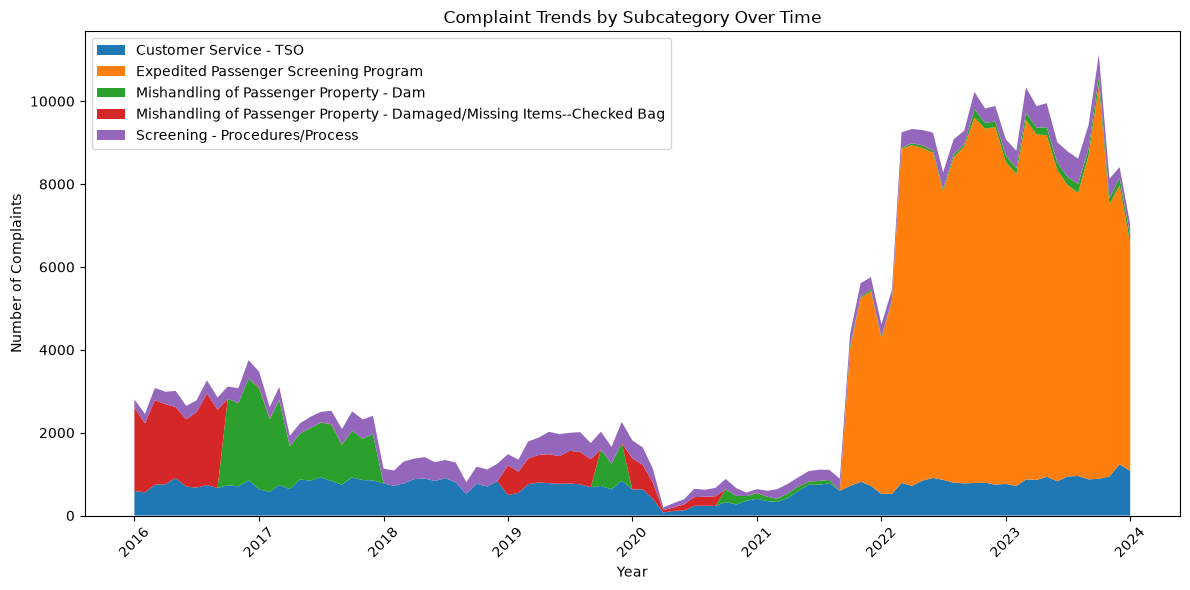

Saved: figures/complaint_trends_by_subcategory_over_time.jpg


In [7]:
top_subcats = (
    subcategory_df
    .groupby("subcategory")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
    .tolist()
)

area_data = subcategory_df[
    subcategory_df["subcategory"].isin(top_subcats)
]

area_pivot = area_data.pivot_table(
    index="year_month",
    columns="subcategory",
    values="count",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(12, 6))

plt.stackplot(
    area_pivot.index,
    area_pivot.T,
    labels=area_pivot.columns
)

plt.title("Complaint Trends by Subcategory Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Complaints")
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()

save_path = (
    FIGURES_DIR
    / "complaint_trends_by_subcategory_over_time.jpg"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figures/"
    "complaint_trends_by_subcategory_over_time.jpg"
)


### Detailed Interpretation — Complaint Subcategory Trends

**How to read this figure.** Each colored band represents one of the **five subcategories with the highest cumulative complaint counts**. The thickness of a band indicates that subcategory's monthly volume; the combined height is the sum of these **five selected subcategories only**, not the total across every complaint type. The plot is therefore best used to compare the composition and timing of the leading concerns.

**Expedited screening is the main driver among the selected groups.** The subcategory **Expedited Passenger Screening Program** contains **380,103 complaints**. A separately labeled subcategory, **Expedited Passenger Screening Program - TSA PreCheck**, contains **141,096**. Both relate to expedited screening, but they are distinct source labels; merging them would require an explicit, documented recoding decision. Their prominence suggests that expedited-screening experiences deserve a focused review.

**Other concerns remain visible.** **Customer Service - TSO (69,081)** and **Screening - Procedures/Process (37,903)** indicate that passenger interactions and procedural issues also generate substantial complaint volume. These areas should not be overlooked simply because the expedited-screening bands are larger.

**Change over time.** The expanded area after 2021 indicates that the leading subcategories contribute to the broader rise in reported complaints seen in the heatmap. However, a rising band can reflect more travelers, changes in reporting, or genuine process problems. The figure alone cannot distinguish among those explanations. Nor does the stacked presentation prove that a smaller subcategory is unimportant: lower-volume issues may still have high operational severity.

**Business and operational implications.** The most actionable next analysis would examine expedited-screening complaints by airport and month, then review specific complaint narratives or finer categories where available. Comparing those counts against expedited-screening passenger volumes could reveal whether the apparent concentration is simply proportional to use of the program. The findings suggest **where to investigate**, not a proven root cause or a validated intervention.

## 7. Monthly Complaint Distribution Across Top Airports

The boxplot compares monthly complaint counts for the ten airports with the highest cumulative totals. The central line is the median month, the box describes the middle half of monthly observations, and points beyond the whiskers indicate unusually high or low months under the boxplot rule.


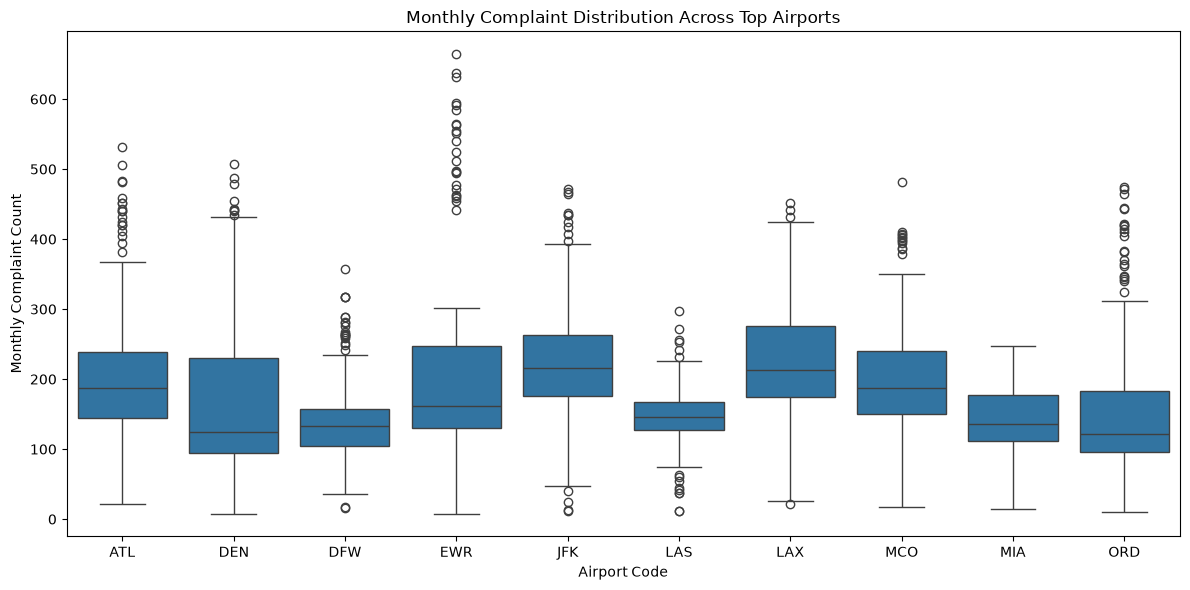

Saved: figures/monthly_complaint_distribution_top_airports.jpg


In [8]:
top_airports = (
    airport_df
    .groupby("airport")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
    .tolist()
)

boxplot_data = airport_df[
    airport_df["airport"].isin(top_airports)
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=boxplot_data,
    x="airport",
    y="count"
)

plt.title(
    "Monthly Complaint Distribution Across Top Airports"
)
plt.xlabel("Airport Code")
plt.ylabel("Monthly Complaint Count")
plt.tight_layout()

save_path = (
    FIGURES_DIR
    / "monthly_complaint_distribution_top_airports.jpg"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figures/"
    "monthly_complaint_distribution_top_airports.jpg"
)


### Detailed Interpretation — Monthly Complaint Distribution at Major Airports

**Selection and meaning.** The boxplot includes the **ten airports with the highest cumulative complaint counts** in the airport-level data. Each airport's box summarizes its distribution of monthly counts: the center line is the median, the box spans the middle 50% of observations, and the whiskers and outlying points help show more unusual months. This is a comparison of **monthly variability**, not just a ranking of totals.

**Highest overall totals.** **LAX recorded 24,794**, **JFK 24,677**, and **EWR 24,405** complaints. **ATL (23,591)** and **MCO (22,308)** follow. LAX exceeds JFK by only **117 complaints** over the full observed period, so the leading airports are relatively close in cumulative volume. These totals should not be mistaken for the median monthly values displayed inside the boxes.

**Why the spread matters.** Two airports can accumulate similar totals but have different month-to-month patterns. A taller box suggests greater variation across typical months; points beyond the whiskers flag months that merit closer examination. A high outlier is not automatically an error or a service failure—it could reflect unusually high passenger volume, a short-lived operational event, or reporting changes. The chart provides a way to identify such months for follow-up.

**Selection effect.** Because airports were chosen based on their total complaints, this view emphasizes large complaint-volume airports. It does not establish that these airports perform worse than smaller facilities, and it should not be used as a nationwide airport quality ranking.

**Operational interpretation.** For a fair comparison, calculate complaints per million screened passengers by airport and month, and examine complaint categories during the highest-count months. This would help distinguish persistent baseline workload from unusual spikes and make resource-allocation decisions more defensible.

## 8. Spatial Distribution of TSA Complaints by Airport

The scatterplot matches TSA airport codes to coordinates in the airport reference dataset. Marker size represents cumulative complaints for the 50 highest-count matched airports, and labels identify the leading ten. The figure is a longitude–latitude scatterplot, not a geographic boundary map.


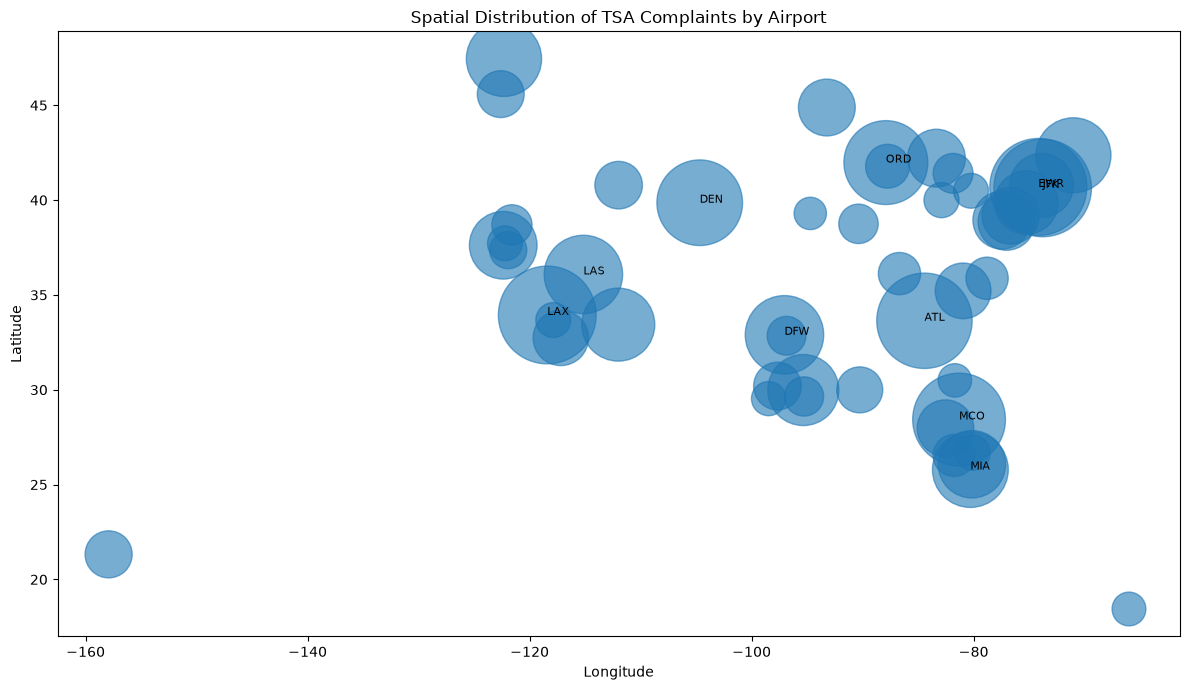

Saved: figures/spatial_distribution_of_tsa_complaints.jpg


In [9]:
airport_map_df = airport_df.merge(
    iata_df,
    left_on="airport",
    right_on="iata",
    how="left"
)

airport_map_df = airport_map_df.dropna(
    subset=["latitude", "longitude"]
)

map_data = (
    airport_map_df
    .groupby(
        [
            "airport_x",
            "latitude",
            "longitude"
        ]
    )["count"]
    .sum()
    .reset_index()
    .sort_values(
        "count",
        ascending=False
    )
    .head(50)
)

plt.figure(figsize=(12, 7))

plt.scatter(
    map_data["longitude"],
    map_data["latitude"],
    s=map_data["count"] / 5,
    alpha=0.6
)

for _, row in map_data.head(10).iterrows():
    plt.text(
        row["longitude"],
        row["latitude"],
        row["airport_x"],
        fontsize=8
    )

plt.title(
    "Spatial Distribution of TSA Complaints by Airport"
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()

save_path = (
    FIGURES_DIR
    / "spatial_distribution_of_tsa_complaints.jpg"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figures/"
    "spatial_distribution_of_tsa_complaints.jpg"
)


### Detailed Interpretation — Spatial Distribution of Airport Complaints

**What is plotted.** Airport-level complaint records are joined to the IATA/ICAO reference file using airport codes, then mapped using available latitude and longitude. Marker size represents **cumulative recorded complaints**. The chart shows the **50 highest-count airports among those successfully matched to coordinates**, rather than all airports in the complaint dataset.

**Geographic pattern.** Larger markers cluster around major U.S. metropolitan airport areas, including California and the northeastern United States. This agrees with the airport ranking, where **LAX, JFK, and EWR** appear among the highest-total locations. The map helps communicate *where* recorded complaints are concentrated; it does not reveal why those concentrations occur.

**Interpret marker size carefully.** Large markers are expected at airports serving substantial passenger traffic, even when complaint rates are relatively low. Conversely, a small marker can represent an airport with fewer travelers but a comparatively high rate. The map therefore visualizes complaint **burden**, not passenger-adjusted risk or the quality of security screening.

**Coverage and matching limitations.** The geographic join uses an **international** airport reference table. Records without usable coordinates are excluded, and code matches should be checked for completeness and plausibility. The map is not a comprehensive depiction of every airport in the original complaint records. Geographic proximity also does not imply that neighboring airports share the same complaint causes.

**Operational interpretation.** This visualization can guide where to investigate concentrated complaint workloads or coordinate regional reviews. A more informative next version could report match coverage, use U.S.-only reference records when appropriate, and map passenger-adjusted complaint rates alongside raw totals.

## 9. Complaint Category Ranking

The lollipop chart ranks the ten complaint categories with the highest cumulative counts. Category totals provide a broader perspective than the preceding subcategory chart; the two views should be interpreted separately rather than added together.


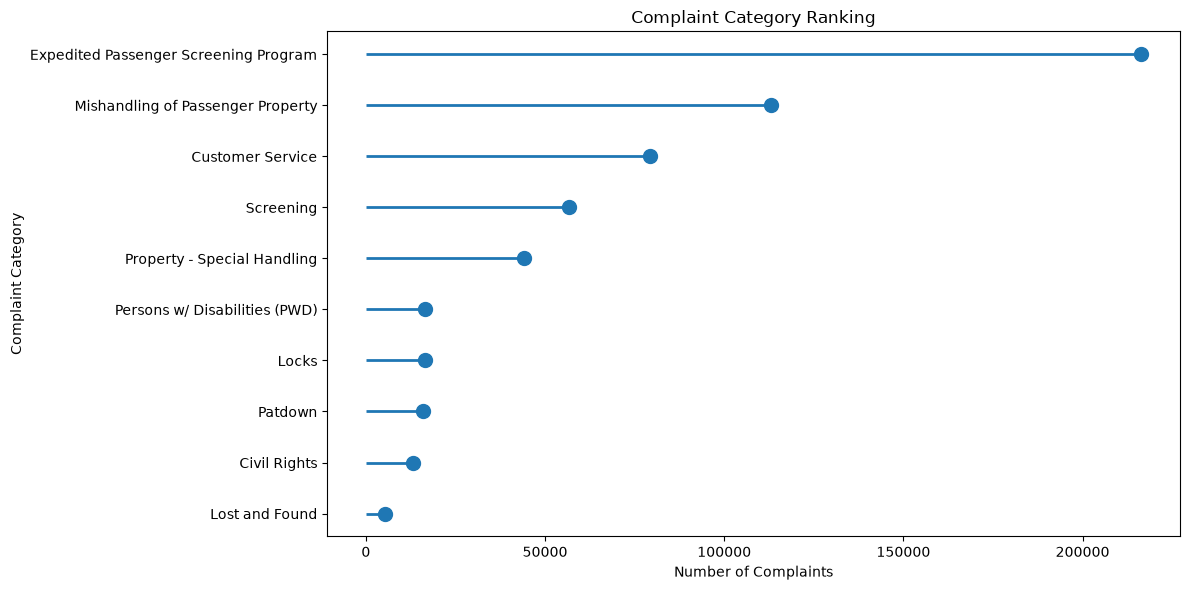

Saved: figures/complaint_category_ranking.jpg


In [10]:
top_categories = (
    category_df
    .groupby("category")["count"]
    .sum()
    .sort_values(ascending=True)
    .tail(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.hlines(
    y=top_categories["category"],
    xmin=0,
    xmax=top_categories["count"],
    linewidth=2
)

plt.scatter(
    top_categories["count"],
    top_categories["category"],
    s=100
)

plt.title("Complaint Category Ranking")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Category")
plt.tight_layout()

save_path = (
    FIGURES_DIR
    / "complaint_category_ranking.jpg"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figures/"
    "complaint_category_ranking.jpg"
)


### Detailed Interpretation — Complaint Category Ranking

**What the ranking shows.** The lollipop chart orders the **ten categories with the highest cumulative complaint counts** in the category-level dataset. Its horizontal scale represents absolute reported complaints. Unlike the preceding subcategory chart, this figure summarizes **broader complaint categories**; category and subcategory totals should not be added together as if they describe independent complaints.

**Dominant category.** **Expedited Passenger Screening Program accounts for 569,943 complaints** out of **1,021,281** in the original category dataset, or approximately **55.8%**. This means more than half of category-level recorded complaints fall under this label. The concentration is strong enough to make expedited screening a logical priority for further diagnostic analysis, although it does not prove the underlying cause.

**Important secondary categories.** **Mishandling of Passenger Property (128,271)** is the next-largest reported category, followed by **Customer Service (82,168)** and **Screening (64,939)**. These represent different aspects of the passenger experience—handling belongings, interactions with personnel, and screening procedures—and would likely require different kinds of operational review.

**Relative size is not the same as severity.** A frequent complaint may be relatively minor, while an infrequent issue may involve substantial harm or require urgent attention. The ten-category cutoff also omits lower-volume categories. Ranking by count is useful for prioritizing workload analysis, but a complete service-improvement strategy would also consider complaint severity, resolution time, recurrence, and passenger exposure.

**Operational interpretation.** A practical follow-up would break the leading categories down by airport and month, identify whether their proportions change over time, and compare those proportions with passenger throughput. This would turn a descriptive ranking into a more targeted investigation without claiming that the chart alone validates a particular policy change.

## 10. Airport Distribution by Region

This bar chart counts airport entries in the **IATA/ICAO reference dataset** by `region_name`. It is a reference-data inventory, not a plot of TSA complaints and not a U.S.-only airport distribution.


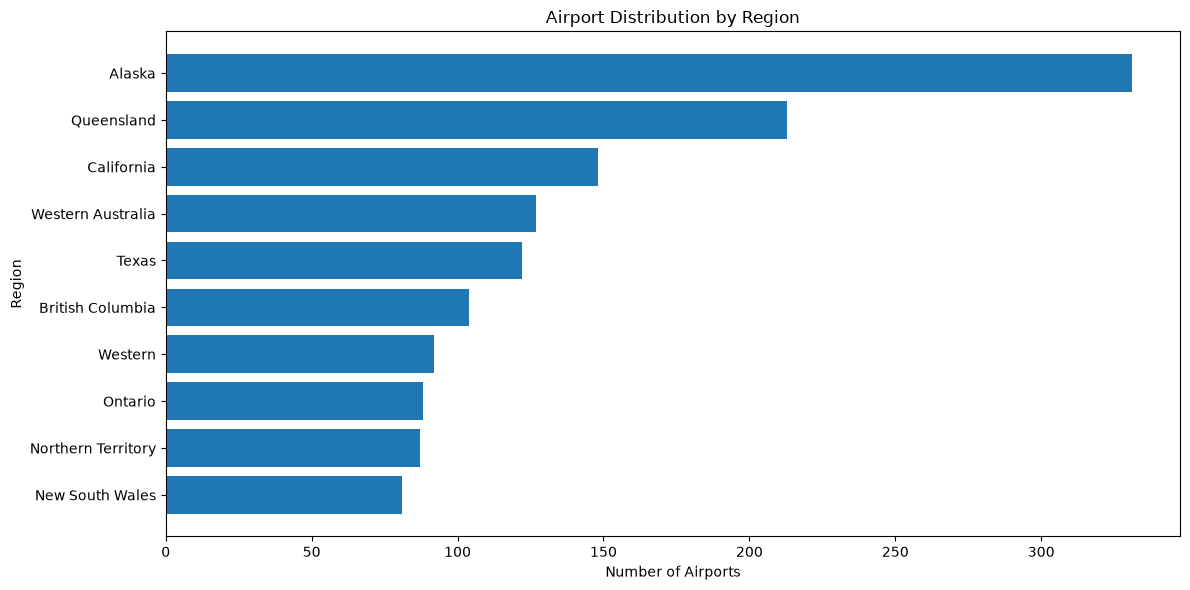

Saved: figures/airport_distribution_by_region.jpg


In [11]:
region_counts = (
    iata_df
    .groupby("region_name")["iata"]
    .count()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="airport_count")
)

plt.figure(figsize=(12, 6))

plt.barh(
    region_counts["region_name"],
    region_counts["airport_count"]
)

plt.title("Airport Distribution by Region")
plt.xlabel("Number of Airports")
plt.ylabel("Region")
plt.gca().invert_yaxis()
plt.tight_layout()

save_path = (
    FIGURES_DIR
    / "airport_distribution_by_region.jpg"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: figures/"
    "airport_distribution_by_region.jpg"
)


### Detailed Interpretation — Regional Coverage of the Airport Reference File

**What this chart actually measures.** The bars count entries with IATA codes in the **international `iata-icao.csv` reference file**, grouped by `region_name`. They do **not** count TSA complaints, and they do **not** show the distribution of airports involved in the complaint dataset. This distinction is essential because the chart is about reference-data coverage rather than passenger experience.

**Leading regions in the reference data.** **Alaska has 331 airport entries**, followed by **Queensland (213)**, **California (148)**, **Western Australia (127)**, and **Texas (122)**. The presence of Australian regions confirms that the source file extends beyond the United States. Comparing these bar lengths does not tell us which region generated more TSA complaints.

**Why the pattern matters to the analysis.** The airport reference provides geographic coordinates used in the preceding map. Its uneven distribution of entries across regions may influence how completely airport codes can be matched, particularly if the reference includes many small airports or airfields that never appear in the TSA complaint data. A large reference count for a region is not evidence of higher TSA operational activity.

**Interpretation boundary.** This figure cannot support claims about which U.S. state has the most TSA complaints, the greatest passenger traffic, or the worst screening performance. Those questions require joining actual TSA complaint records to valid U.S. airport locations and, for rate comparisons, adding passenger-screening denominators.

**Recommended next analytical step.** If the portfolio goal is U.S. regional comparison, filter the reference to `country_code == "US"`, verify the airport-code join, and aggregate **matched complaint totals** by state or region rather than counting reference entries. That would require changing and rerunning the chart's Python code. The current notebook deliberately retains the original calculation, so its label and interpretation must remain explicitly limited to **international reference-data coverage**.

## 11. Saved Project Outputs

The notebook exports six `.jpg` figures into the project's `figures/` directory. The final listing provides a simple check that the expected charts were generated and saved.


In [12]:
print("Figures saved:")

for file in sorted(FIGURES_DIR.glob("*.jpg")):
    print(" -", f"figures/{file.name}")


Figures saved:
 - figures/airport_distribution_by_region.jpg
 - figures/complaint_activity_by_month_and_year_heatmap.jpg
 - figures/complaint_category_ranking.jpg
 - figures/complaint_trends_by_subcategory_over_time.jpg
 - figures/monthly_complaint_distribution_top_airports.jpg
 - figures/spatial_distribution_of_tsa_complaints.jpg


## Conclusion

The TSA complaint analysis shows that complaint volume varies substantially by year, complaint type, and airport. Airport-level complaints declined from **112,610 in 2019** to **45,326 in 2020**, then rose to **172,729 in 2023**. The available **2024 data contains January only**, so it is not comparable with full prior years. Expedited Passenger Screening Program complaints are the largest category (**569,943**), while **LAX, JFK, and EWR** have the highest cumulative airport-level complaint counts in the source data.

The six visualizations offer complementary perspectives: temporal change, subcategory composition, airport-to-airport variation, geographic concentration, category ranking, and airport-reference coverage. Together, they can help identify which processes, locations, and time periods deserve closer operational review. A useful next step would be to incorporate monthly screened-passenger counts and compare complaint rates, not only totals.

### Limitations

- **Counts versus rates:** No passenger-throughput denominator is included, so airport comparisons do not measure complaints per traveler or establish relative service quality.
- **Incomplete period:** January 2024 is the only 2024 month in the uploaded complaint data.
- **Category interpretation:** Subcategory labels overlap conceptually, and the category and subcategory files represent alternate groupings of the same complaint activity.
- **Geographic coverage:** The coordinate plot excludes airports without matching coordinates; the regional chart counts airports in an international reference dataset rather than U.S. TSA complaint locations.
- **Descriptive analysis:** The charts identify associations and changes in reported counts, not the causes of complaints or the effects of policy decisions.
